# Exploración de los datos de Respira MAD

Este cuaderno revisa, fuente por fuente, los datos **tal como se publican**
(sin limpiar) y muestra con gráficos lo que se cuenta en `DATA_AUDIT.md`.

Fuentes:

| Fuente | Qué es | Archivos |
|---|---|---|
| Comunidad de Madrid, calidad del aire | Datos horarios desde 2019 (un CSV por año) | `model_data/air_raw/comunidad_*.csv` |
| Ayuntamiento de Madrid, calidad del aire | Datos horarios (un zip por año + archivo actual) | `model_data/air_raw/city_*` |
| Red Palinocam (Comunidad), polen | Datos diarios desde 1993, todos los tipos | `model_data/pollen_raw/` |
| Open-Meteo, tiempo | Lo que descargaron los modelos | `model_data/weather_*.csv`, `air_weather_zone*.csv` |

**Cómo ejecutarlo:** `.venv/bin/jupyter lab notebooks/exploracion_datos.ipynb`
y después *Run → Run All Cells* (o celda a celda con Mayús + Intro).

Si faltan los archivos de aire, se descargan con
`.venv/bin/python -c "from air_model import history; history.load()"`.
Los de polen se descargan solos la primera vez (unos 140 MB).
La primera ejecución tarda unos minutos; después se usan copias en `model_data/audit/`.

In [1]:
# Preparación: el código de lectura y de comprobación está en data_audit.py (carpeta principal)
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data_audit as A
import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

In [2]:
# Cargar las tres fuentes, sin limpiar (con huecos, banderas y el archivo de origen de cada fila)
air = A.load_air(first_year=2019)        # aire: una fila por estación, contaminante y hora
pollen = A.load_pollen()                 # polen: una fila por captador, día y tipo
daily_weather, hourly_weather = A.load_weather()

print(f"Aire:  {len(air):,} horas · {air['station_code'].nunique()} estaciones · {air['timestamp'].min():%d/%m/%Y} a {air['timestamp'].max():%d/%m/%Y}")
print(f"Polen: {len(pollen):,} filas · {pollen['station_code'].nunique()} captadores · {pollen['date'].min():%d/%m/%Y} a {pollen['date'].max():%d/%m/%Y}")
print(f"Tiempo: {len(daily_weather):,} días (polen) y {len(hourly_weather):,} horas (aire)")

Aire:  9,860,784 horas · 52 estaciones · 01/01/2019 a 01/11/2026
Polen: 3,270,843 filas · 11 captadores · 01/05/1993 a 17/11/2026
Tiempo: 86,555 días (polen) y 549,504 horas (aire)


## 1. Polen

### 1.1 ¿Los días sin dato se tratan como cero?

En los archivos de la Red Palinocam una casilla vacía puede significar dos cosas
distintas: **no se midió** (el captador no funcionó) o **no se contó ese tipo**.
Un cero, en cambio, es una medida: no había granos de ese tipo.

Clasificamos cada día de cada captador:

- **completo**: todos los tipos publicados tienen número;
- **todo en blanco**: ningún tipo tiene número (el captador no midió ese día);
- **parcial**: unos tipos tienen número y otros no.

kind
completo          106781
todo en blanco      8882
parcial             6176


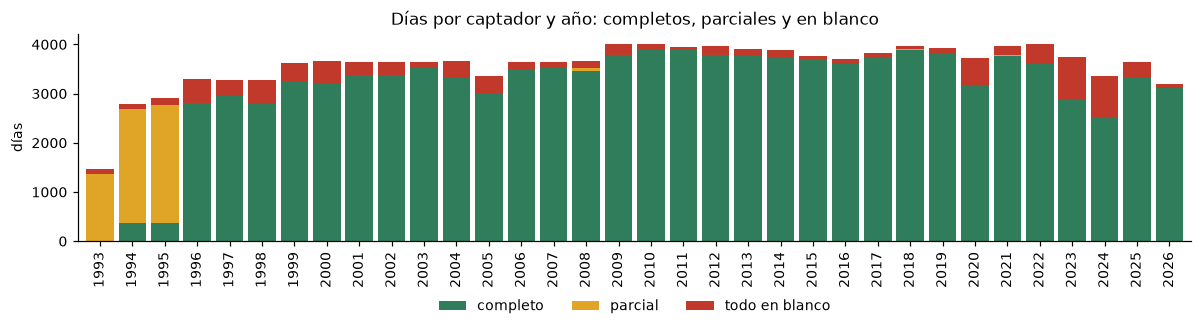

In [3]:
days = A.pollen_day_kinds(pollen)
counts = days["kind"].value_counts()
print(counts.to_string())

by_year = days.assign(year=days["date"].dt.year).groupby(["year", "kind"]).size().unstack(fill_value=0)
by_year[["completo", "parcial", "todo en blanco"]].plot.bar(stacked=True, figsize=(11, 3.2), width=0.85,
                                                            color=["#2f7d5b", "#e0a526", "#c0392b"])
plt.title("Días por captador y año: completos, parciales y en blanco")
plt.ylabel("días"); plt.xlabel(""); plt.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

**Qué vemos.** Los días *parciales* se concentran en 1993–1995 (el primer año
solo se contaron las gramíneas y el eucalipto no se contó hasta 1996). Los días
*en blanco* son huecos reales del captador.

**Qué hace hoy nuestro código:** una casilla vacía se queda como *sin dato*
(nunca se convierte en cero). El modelo usa la última lectura conocida, como
mucho 10 días, y sabe cuántos días tiene.

El riesgo contrario existe: **ceros que en realidad son "no se midió"**. Un
captador que funciona casi siempre recoge algo. Buscamos días en los que *todos*
los tipos son exactamente 0 mientras el resto de la red ve más de 100 granos/m³:

In [4]:
false_zeros = A.pollen_false_zeros(pollen, network_min=100)
print(f"Días con todos los tipos a 0 mientras la red ve > 100 granos/m³: {len(false_zeros)}")
false_zeros.sort_values("network_median", ascending=False).head(12)[["station_code", "date", "numbers", "network_median"]]

Días con todos los tipos a 0 mientras la red ve > 100 granos/m³: 49


,station_code,date,numbers,network_median
17318,ALCO,2008-04-06,1,1097.0
34380,ALER,2024-12-02,27,794.0
30388,ALER,2011-04-10,27,587.0
17319,ALCO,2008-04-07,1,517.5
51328,AYTM,2008-04-07,1,517.5
51294,AYTM,2008-03-04,1,376.0
63169,COSL,2008-03-04,1,376.0
20984,ALCO,2018-05-21,26,342.0
51321,AYTM,2008-03-31,1,287.0
87614,GETA,2008-03-02,1,280.0


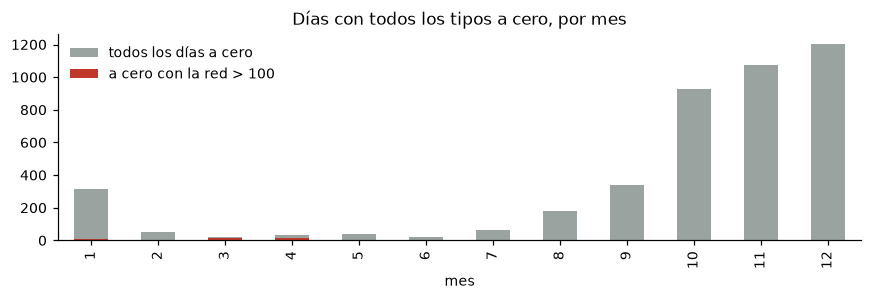

In [5]:
# Dónde caen: casi todos los días "todo a cero" son de otoño-invierno (creíbles);
# los de primavera con la red alta son los sospechosos.
allzero = days[(days["numbers"] > 0) & (days["total"] == 0)]
fig, ax = plt.subplots(figsize=(8, 2.8))
allzero["date"].dt.month.value_counts().sort_index().plot.bar(ax=ax, color="#9aa3a0", label="todos los días a cero")
false_zeros["date"].dt.month.value_counts().reindex(range(1, 13), fill_value=0).plot.bar(ax=ax, color="#c0392b", label="a cero con la red > 100")
ax.set_title("Días con todos los tipos a cero, por mes"); ax.set_xlabel("mes"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 1.2 Cobertura por captador y año

Porcentaje de días del año con al menos un dato. Los huecos grandes cambian
cuánto se puede aprender (o comprobar) en cada año.

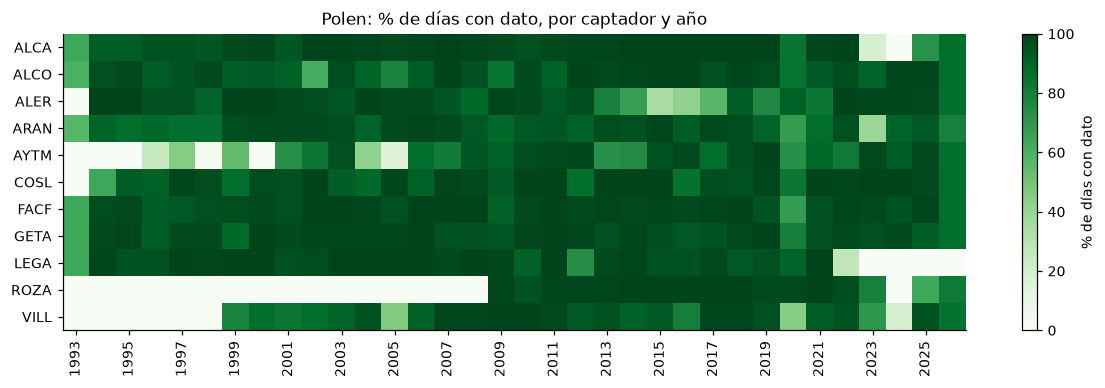

year,2019,2020,2021,2022,2023,2024,2025,2026
station_code,,,,,,,,
ALCA,100.0,84.0,99.0,100.0,18.0,0.0,72.0,87.0
ALCO,97.0,84.0,93.0,97.0,90.0,99.0,99.0,87.0
ALER,76.0,91.0,83.0,100.0,99.0,99.0,98.0,86.0
ARAN,90.0,68.0,87.0,96.0,39.0,90.0,93.0,79.0
AYTM,100.0,73.0,89.0,82.0,98.0,92.0,98.0,86.0
COSL,99.0,83.0,100.0,99.0,100.0,100.0,98.0,87.0
FACF,95.0,68.0,96.0,99.0,98.0,95.0,99.0,86.0
GETA,100.0,80.0,96.0,98.0,96.0,98.0,92.0,87.0
LEGA,96.0,90.0,100.0,27.0,0.0,0.0,0.0,0.0


In [6]:
coverage = A.pollen_coverage(pollen)
fig, ax = plt.subplots(figsize=(11, 3.6))
image = ax.imshow(coverage.values, aspect="auto", cmap="Greens", vmin=0, vmax=100)
ax.set_yticks(range(len(coverage.index)), coverage.index)
ax.set_xticks(range(0, len(coverage.columns), 2), coverage.columns[::2], rotation=90)
plt.colorbar(image, label="% de días con dato")
ax.set_title("Polen: % de días con dato, por captador y año")
plt.tight_layout(); plt.show()
coverage.loc[:, 2019:]

**Qué vemos.** Leganés (LEGA) dejó de medir en abril de 2022. Alcalá (ALCA) casi
no tiene datos en 2023–2024 y Las Rozas (ROZA) ninguno en 2024: **el año que
usamos para elegir modelos (2024) tiene tres captadores menos**. 2020 baja en todos
(confinamiento).

### 1.3 Nombres de tipos, codificación y fechas

Los archivos no son todos iguales: cambia la codificación de caracteres, el
formato de la fecha y, en 2021–2022, algunos nombres llevan un "?" en lugar de la
letra con tilde.

In [7]:
files = pollen.groupby("file", observed=True).agg(filas=("value", "size"), codificacion=("encoding", "first"),
                                                 formato_fecha=("date_format", "first"))
print(files.groupby(["codificacion", "formato_fecha"]).size().rename("archivos").to_string())
broken = pollen[pollen["type_raw"].astype(str).str.contains("?", regex=False)]
print(f"\nFilas con nombre roto: {len(broken):,}")
broken.groupby(["file", "type_raw"], observed=True).size().rename("filas")

codificacion  formato_fecha
latin-1       AAAA/MM/DD       31
utf-8         AAAA-MM-DD        2
              AAAA/MM/DD        2



Filas con nombre roto: 39,955


file           type_raw                   
hist_2021.csv  Casta?o                        3978
               Cupres?ceas/Tax?ceas           3978
               Gram?neas                      3978
               Pl?tano de paseo               3978
               Quenopodi?ceas/Amarant?ceas    3978
hist_2022.csv  Casta?o                        4013
               Cupres?ceas/Tax?ceas           4013
               Gram?neas                      4013
               Pl?tano de paseo               4013
               Quenopodi?ceas/Amarant?ceas    4013
Name: filas, dtype: int64

In [8]:
# Duplicados: la misma fila (captador, día, tipo) más de una vez. ¿Coinciden las copias?
key = ["station_code", "date", "type"]
dups = pollen[pollen.duplicated(key, keep=False) & pollen["value"].notna()]
agree = dups.groupby(key, observed=True)["value"].agg(["min", "max", "count"])
agree = agree[agree["count"] > 1]
print(f"Grupos duplicados con dos o más números: {len(agree):,} · copias distintas: {(agree['max'] != agree['min']).sum()}")
print(dups.groupby("file", observed=True).size().loc[lambda s: s > 0].rename("filas duplicadas").to_string())

Grupos duplicados con dos o más números: 82,370 · copias distintas: 0
file
current.csv      79650
hist_2012.csv     2717
hist_2013.csv      446
hist_2014.csv        4
hist_2015.csv      412
hist_2016.csv      124
hist_2017.csv      268
hist_2018.csv      590
hist_2019.csv      308
hist_2020.csv      918
hist_2025.csv      270
hist_2026.csv    79299


### 1.4 Distribuciones y valores extremos

El polen tiene muchos días a cero y unos pocos días enormes, por eso las
gráficas usan escala logarítmica ($\log(1 + x)$).

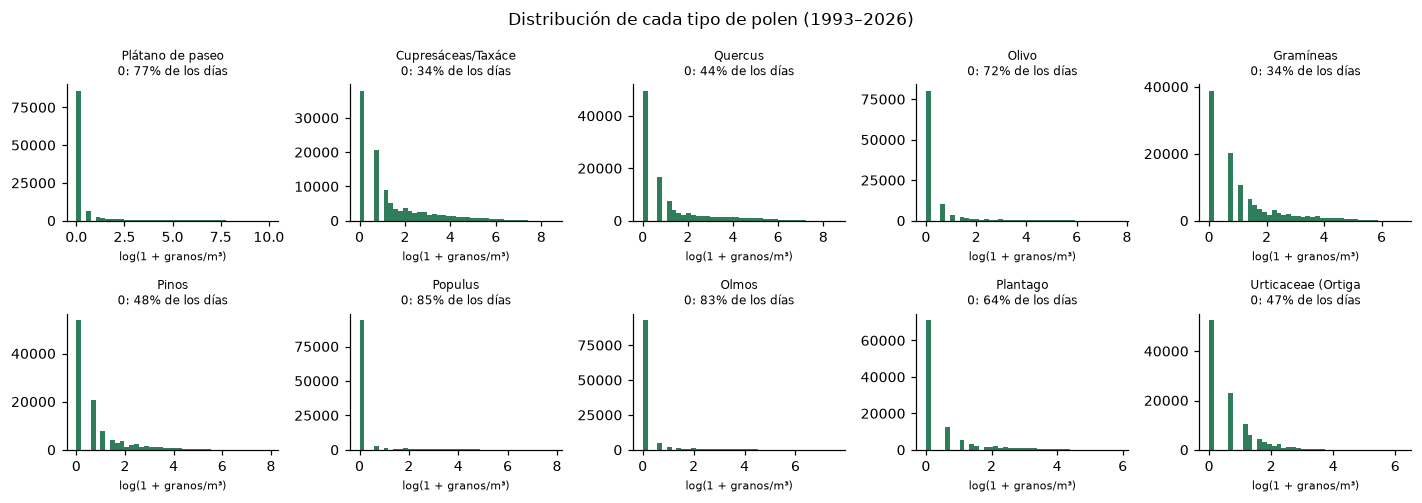

,count,mean,std,min,50%,90%,99%,99.9%,max
type,,,,,,,,,
Cupresáceas/Taxáceas,111503.0,30.0,132.0,0.0,1.0,49.0,565.0,1743.0,4777.0
Gramíneas,112885.0,11.0,33.0,0.0,1.0,24.0,166.0,363.0,810.0
Olivo,111512.0,8.0,46.0,0.0,0.0,8.0,194.0,613.0,2124.0
Olmos,111502.0,4.0,28.0,0.0,0.0,3.0,105.0,373.0,1926.0
Pinos,111516.0,8.0,37.0,0.0,1.0,15.0,147.0,491.0,2736.0
Plantago,111512.0,4.0,13.0,0.0,0.0,10.0,63.0,144.0,353.0
Plátano de paseo,111512.0,39.0,342.0,0.0,0.0,9.0,941.0,4477.0,22056.0
Populus,111503.0,5.0,36.0,0.0,0.0,4.0,112.0,467.0,2440.0
Quercus,111522.0,27.0,127.0,0.0,1.0,49.0,516.0,1625.0,5054.0


In [9]:
ten = pollen[pollen["type"].isin(A.POLLEN_TYPES) & pollen["value"].notna()].drop_duplicates(key)
fig, axes = plt.subplots(2, 5, figsize=(13, 4.6), sharey=False)
for ax, pollen_type in zip(axes.flat, A.POLLEN_TYPES):
    values = ten.loc[ten["type"] == pollen_type, "value"]
    ax.hist(np.log1p(values), bins=40, color="#2f7d5b")
    ax.set_title(f"{pollen_type[:18]}\n0: {(values == 0).mean():.0%} de los días", fontsize=8)
    ax.set_xlabel("log(1 + granos/m³)", fontsize=7)
plt.suptitle("Distribución de cada tipo de polen (1993–2026)"); plt.tight_layout(); plt.show()
ten.groupby("type", observed=True)["value"].describe(percentiles=[.5, .9, .99, .999]).round(0)

      date   value
2011-04-01 22056.0
2011-03-31 17545.0
2010-04-10 16595.0
2019-03-23 16448.0
2011-03-30 14939.0
2009-03-24 14593.0
2011-04-03 14145.0
2019-03-22 13984.0
2019-03-25 13829.0
2015-04-01 13230.0


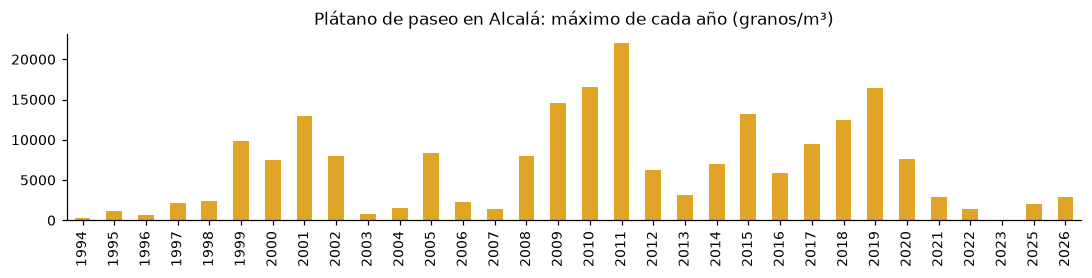

In [10]:
# El valor más alto del archivo: plátano en Alcalá. ¿Error o real? Se repite cada primavera.
alca = ten[(ten["station_code"] == "ALCA") & (ten["type"] == "Plátano de paseo")]
top = alca.nlargest(10, "value")[["date", "value"]]
print(top.to_string(index=False))
peaks = alca.assign(year=alca["date"].dt.year).groupby("year")["value"].max()
peaks.plot.bar(figsize=(10, 2.6), color="#e0a526", title="Plátano de paseo en Alcalá: máximo de cada año (granos/m³)")
plt.xlabel(""); plt.tight_layout(); plt.show()

**Picos aislados.** Un día que es más de 10 veces el anterior y el siguiente
(y al menos 100 granos/m³) puede ser real (un seto de cipreses junto al captador)
o un error de transcripción. Si además el resto de la red ese día ve 10 veces
menos, es dudoso.

In [11]:
ten_sorted = ten.sort_values(key)
group = ten_sorted.groupby(["station_code", "type"], observed=True)
ten_sorted["prev"] = group["value"].shift(1)
ten_sorted["next"] = group["value"].shift(-1)
ten_sorted["step"] = group["date"].diff().dt.days
network = ten_sorted.groupby(["date", "type"], observed=True)["value"].median().rename("network_median")
ten_sorted = ten_sorted.join(network, on=["date", "type"])
spikes = ten_sorted[(ten_sorted["value"] >= 100) & (ten_sorted["step"] == 1)
                    & (ten_sorted["value"] > 10 * ten_sorted["prev"].clip(lower=1))
                    & (ten_sorted["value"] > 10 * ten_sorted["next"].clip(lower=1))]
doubtful_spikes = spikes[spikes["value"] > 10 * spikes["network_median"].clip(lower=1)]
print(f"Picos aislados: {len(spikes)} · sin apoyo de la red: {len(doubtful_spikes)}")
doubtful_spikes["type"].value_counts().loc[lambda s: s > 0]

Picos aislados: 250 · sin apoyo de la red: 63


type
Cupresáceas/Taxáceas    27
Populus                 11
Pinos                    8
Quercus                  5
Gramíneas                3
Olmos                    3
Plátano de paseo         3
Olivo                    2
Plantago                 1
Name: count, dtype: int64

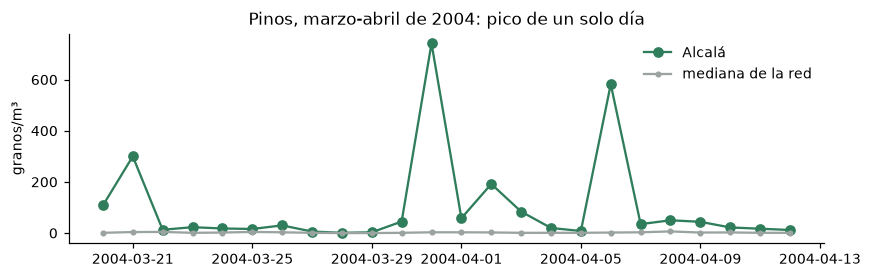

In [12]:
# Un ejemplo: pinos en Alcalá, 31 de marzo de 2004 (742 granos/m³; la red, 3)
example = ten_sorted[(ten_sorted["station_code"] == "ALCA") & (ten_sorted["type"] == "Pinos")
                     & ten_sorted["date"].between("2004-03-20", "2004-04-12")]
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(example["date"], example["value"], marker="o", color="#2f7d5b", label="Alcalá")
ax.plot(example["date"], example["network_median"], marker=".", color="#9aa3a0", label="mediana de la red")
ax.set_title("Pinos, marzo-abril de 2004: pico de un solo día"); ax.set_ylabel("granos/m³"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 1.5 Curvas estacionales

Cada tipo tiene su temporada. Mediana de toda la red por día del año
(2010–2025) y, para las gramíneas, cada año por separado: los años cambian mucho.

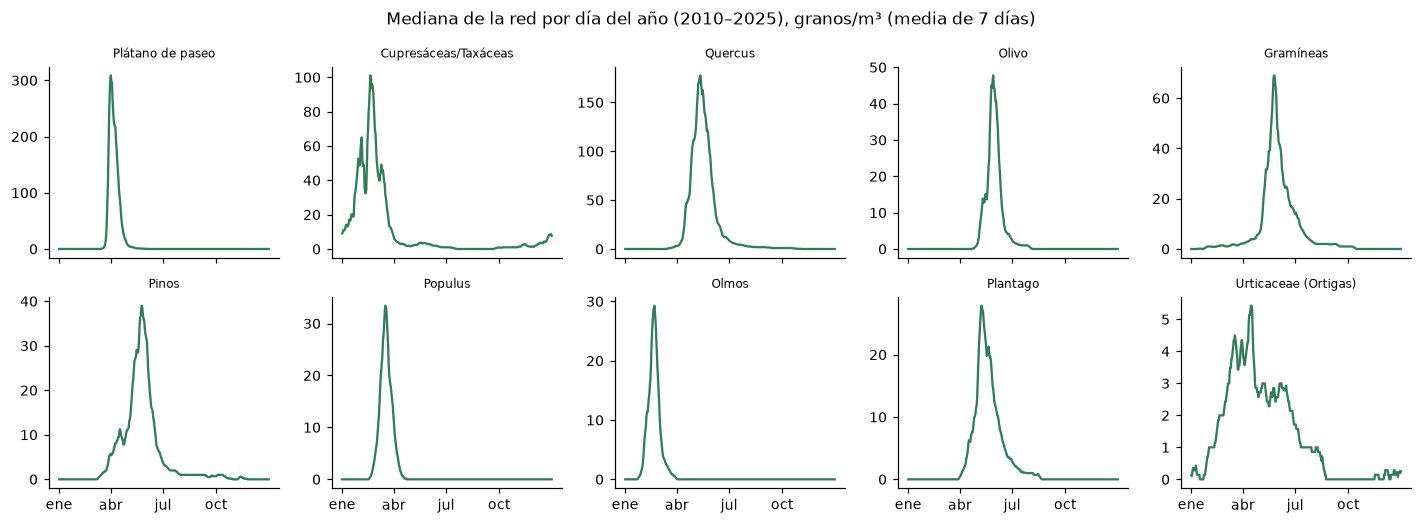

In [13]:
recent = ten[ten["date"].dt.year.between(2010, 2025)].copy()
recent["doy"] = recent["date"].dt.dayofyear
curve = recent.groupby(["type", "doy"], observed=True)["value"].median().unstack(0).rolling(7, center=True, min_periods=1).mean()
fig, axes = plt.subplots(2, 5, figsize=(13, 4.8), sharex=True)
for ax, pollen_type in zip(axes.flat, A.POLLEN_TYPES):
    ax.plot(curve.index, curve[pollen_type], color="#2f7d5b")
    ax.set_title(pollen_type[:20], fontsize=8)
    ax.set_xticks([1, 91, 182, 274], ["ene", "abr", "jul", "oct"])
plt.suptitle("Mediana de la red por día del año (2010–2025), granos/m³ (media de 7 días)"); plt.tight_layout(); plt.show()

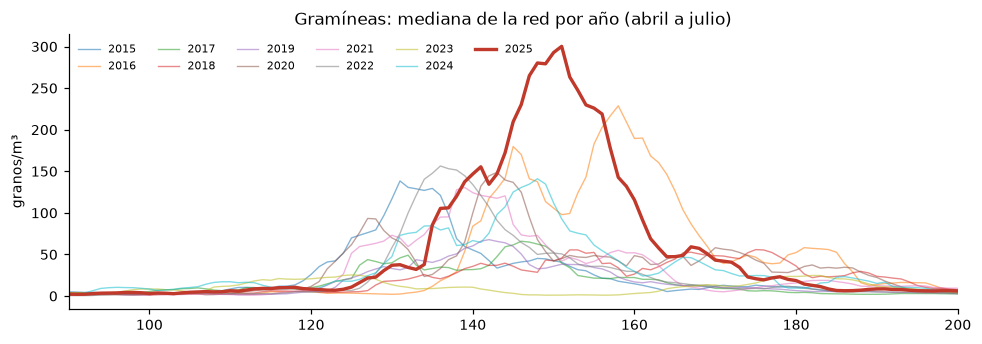

In [14]:
grass = ten[(ten["type"] == "Gramíneas") & ten["date"].dt.year.between(2015, 2025)].copy()
grass["doy"], grass["year"] = grass["date"].dt.dayofyear, grass["date"].dt.year
by_year = grass.groupby(["year", "doy"])["value"].median().unstack(0).rolling(7, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
for year in by_year.columns:
    ax.plot(by_year.index, by_year[year], lw=2.2 if year == 2025 else 0.9, label=str(year),
            color="#c0392b" if year == 2025 else None, alpha=1 if year == 2025 else 0.55)
ax.set_xlim(90, 200); ax.set_title("Gramíneas: mediana de la red por año (abril a julio)"); ax.set_ylabel("granos/m³")
ax.legend(ncol=6, fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 2. Calidad del aire

Cada hora trae una **bandera**: `V` válido, `T` provisional (solo en los datos del
día), `N` no válido. Los modelos solo usan `V` y `T`.

### 2.1 Banderas, valores imposibles y duplicados

In [15]:
air["year"] = air["timestamp"].dt.year
print(air.groupby(["source", "flag"], observed=True).size().unstack(0).fillna(0).astype(int).to_string())
n_flag_with_value = air[(air["flag"] == "N") & air["value"].notna()]
print(f"\nHoras marcadas N que sí traen un número (Ayuntamiento): {len(n_flag_with_value):,}")
print(f"  esos números van de {n_flag_with_value['value'].min():.0f} a {n_flag_with_value['value'].max():,.0f}: ¡nunca se deben usar!")
negative = air[(air["value"] < 0)]
print(f"Valores negativos: {len(negative)} (con bandera V: {(negative['flag'] == 'V').sum()})")
print("Bandera desconocida 'M':")
air[air["flag"] == "M"][["station_code", "pollutant", "timestamp", "value", "source"]]

source  Ayuntamiento de Madrid  Comunidad de Madrid
flag                                               
M                            3                    0
N                        74409               133692
V                      3915516              5737164

Horas marcadas N que sí traen un número (Ayuntamiento): 74,409
  esos números van de -60 a 89,337: ¡nunca se deben usar!
Valores negativos: 239 (con bandera V: 2)
Bandera desconocida 'M':


,station_code,pollutant,timestamp,value,source
6805053,28079040,PM10,2025-01-13 11:00:00,231.0,Ayuntamiento de Madrid
6845826,28079040,PM10,2025-01-13 12:00:00,125.0,Ayuntamiento de Madrid
6886599,28079040,PM10,2025-01-13 13:00:00,88.0,Ayuntamiento de Madrid


Horas duplicadas: 8,760 · copias que no coinciden: 7,761
station_code  pollutant
28123002      O3           8760


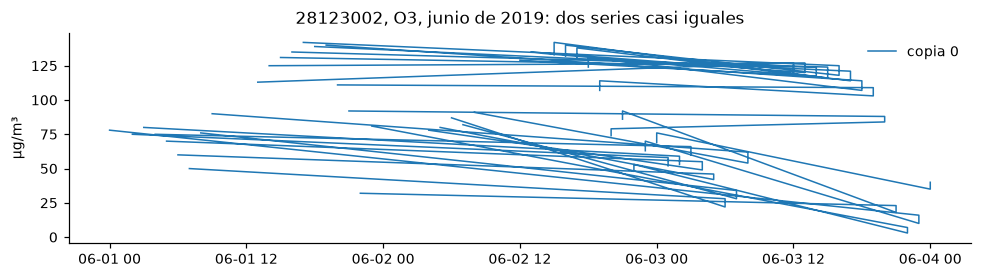

In [16]:
dup_rows, dup_summary = A.air_duplicates(air)
print(f"Horas duplicadas: {len(dup_summary):,} · copias que no coinciden: {(~dup_summary['agree']).sum():,}")
print(dup_summary.groupby(["station_code", "pollutant"], observed=True).size().to_string())
# Son dos analizadores de ozono en la misma estación (punto de muestreo _14_6 y _14_8) en 2019
one = dup_rows[(dup_rows["station_code"] == "28123002") & dup_rows["timestamp"].between("2019-06-01", "2019-06-04")]
fig, ax = plt.subplots(figsize=(9, 2.6))
for order, part in one.groupby("file_order"):
    ax.plot(part["timestamp"], part["value"], label=f"copia {order}", lw=1)
ax.set_title("28123002, O3, junio de 2019: dos series casi iguales"); ax.set_ylabel("µg/m³"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 2.2 Distribuciones y valores extremos

Los valores muy altos se comparan con lo que vieron las demás estaciones a la
misma hora: si todas suben, es un episodio real (por ejemplo, el polvo sahariano
del 15 de marzo de 2022); si sube una sola, es sospechoso.

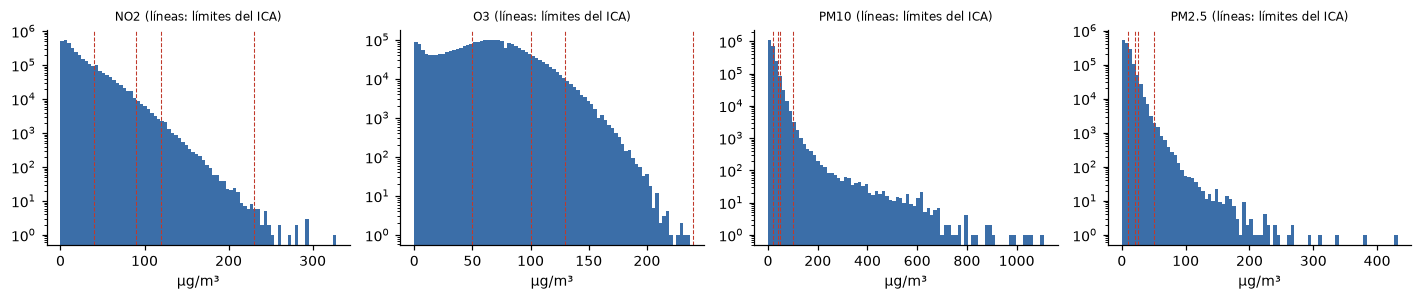

,count,mean,std,min,50%,99%,99.9%,max
pollutant,,,,,,,,
NO2,3330386.0,21.6,21.5,0.0,14.0,98.0,140.0,328.0
O3,2617410.0,60.0,32.9,0.0,61.0,139.0,166.0,237.0
PM10,2213185.0,17.5,17.6,0.0,13.0,76.0,163.0,1109.0
PM2.5,1483168.0,9.5,8.3,-12.0,8.0,39.0,70.0,432.0


In [17]:
valid = air[air["flag"].isin(["V", "T"]) & air["value"].notna()].drop_duplicates(["station_code", "pollutant", "timestamp"])
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, pollutant in zip(axes, ["NO2", "O3", "PM10", "PM2.5"]):
    values = valid.loc[valid["pollutant"] == pollutant, "value"]
    ax.hist(values.clip(lower=0), bins=80, color="#3b6ea8", log=True)
    for limit in config.ICA_BANDS[pollutant][:4]:
        ax.axvline(limit, color="#c0392b", lw=0.7, ls="--")
    ax.set_title(f"{pollutant} (líneas: límites del ICA)", fontsize=8); ax.set_xlabel("µg/m³")
plt.tight_layout(); plt.show()
valid.groupby("pollutant", observed=True)["value"].describe(percentiles=[.5, .99, .999]).round(1)

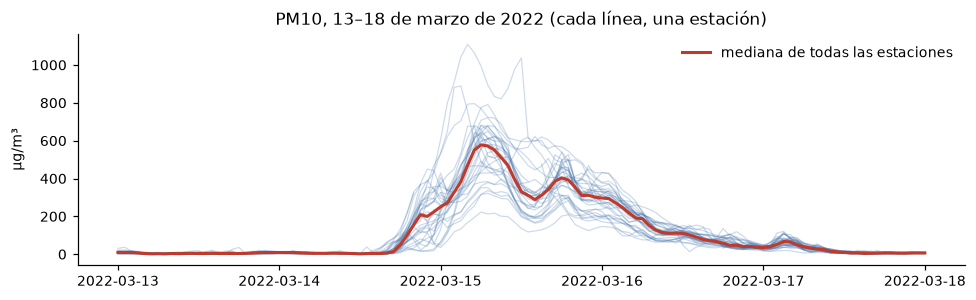

In [18]:
# El máximo de PM10: 15 de marzo de 2022, calima. Todas las estaciones suben a la vez.
day = valid[(valid["pollutant"] == "PM10") & valid["timestamp"].between("2022-03-13", "2022-03-18")]
wide = day.pivot(index="timestamp", columns="station_code", values="value")
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(wide.index, wide.values, color="#3b6ea8", alpha=0.25, lw=0.8)
ax.plot(wide.index, wide.median(axis=1), color="#c0392b", lw=2, label="mediana de todas las estaciones")
ax.set_title("PM10, 13–18 de marzo de 2022 (cada línea, una estación)"); ax.set_ylabel("µg/m³"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 2.3 "Dato dudoso" en la historia

La regla de la aplicación (`config.py`): un valor en Desfavorable o peor
mientras la mediana de las otras estaciones está en las dos mejores categorías, y
más de 4 veces esa mediana. Aplicada a 2019–2026:

In [19]:
doubtful = A.air_doubtful(air)
stations = A.air_stations().set_index("station_code")["station"]
print(f"Horas 'dato dudoso' 2019-2026: {len(doubtful):,} de {len(valid):,} ({len(doubtful) / len(valid):.2%})")
summary = doubtful.groupby(["station_code", "pollutant"]).size().sort_values(ascending=False).head(12).rename("horas").reset_index()
summary["estación"] = summary["station_code"].map(stations)
summary

Horas 'dato dudoso' 2019-2026: 8,341 de 9,644,149 (0.09%)


,station_code,pollutant,horas,estación
0,28047002,PM2.5,644,Collado-Villalba
1,28079050,PM2.5,446,Plaza Castilla
2,28079055,PM10,378,Urb. Embajada
3,28079008,PM2.5,363,Escuelas Aguirre
4,28079056,PM2.5,345,Plaza Elíptica
5,28120001,PM2.5,328,Rascafría
6,28148004,PM2.5,308,Torrejón de Ardoz
7,28079048,PM2.5,274,Castellana
8,28079047,PM2.5,254,Méndez Álvaro
9,28180001,PM2.5,252,Villarejo de Salvanés


**La estación morada (Orusco del Tajuña, 17 de noviembre de 2026).** En directo
la Comunidad publicó PM10 de hasta 437 µg/m³ con bandera `T` (provisional). En el
archivo mensual validado de noviembre, **esas mismas horas aparecen ahora como `N`
(no válidas)**: la propia red las descartó después. Lo comprobamos con el archivo
mensual actual:

In [20]:
import data   # las funciones de descarga de la aplicación
month = data._read_csv(data._ckan_csv_url("calidad_aire_datos_mes"))
orusco = month[(month["municipio"] == "102") & (month["magnitud"] == "10") & month["dia"].astype(int).between(15, 19)]
pd.DataFrame({f"día {row.dia}": [f"{row[f'h{h:02d}'] or '·'} {row[f'v{h:02d}']}" for h in range(1, 25)]
              for _, row in orusco.iterrows()}, index=[f"h{h:02d}" for h in range(1, 25)]).T

2026-11-19 07:55:12.371 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.372 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.373 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.373 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.373 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.373 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.374 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 07:55:12.374 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


,h01,h02,h03,h04,h05,h06,h07,h08,h09,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23,h24
día 15,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V
día 16,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N
día 17,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N
día 18,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,nan N,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V,1 V


### 2.4 Cobertura y huecos por estación

Porcentaje de horas del año con un valor válido. Se ven las estaciones nuevas
(julio de 2023), las que cierran y los huecos largos. 2026 llega hasta el 1 de
noviembre.

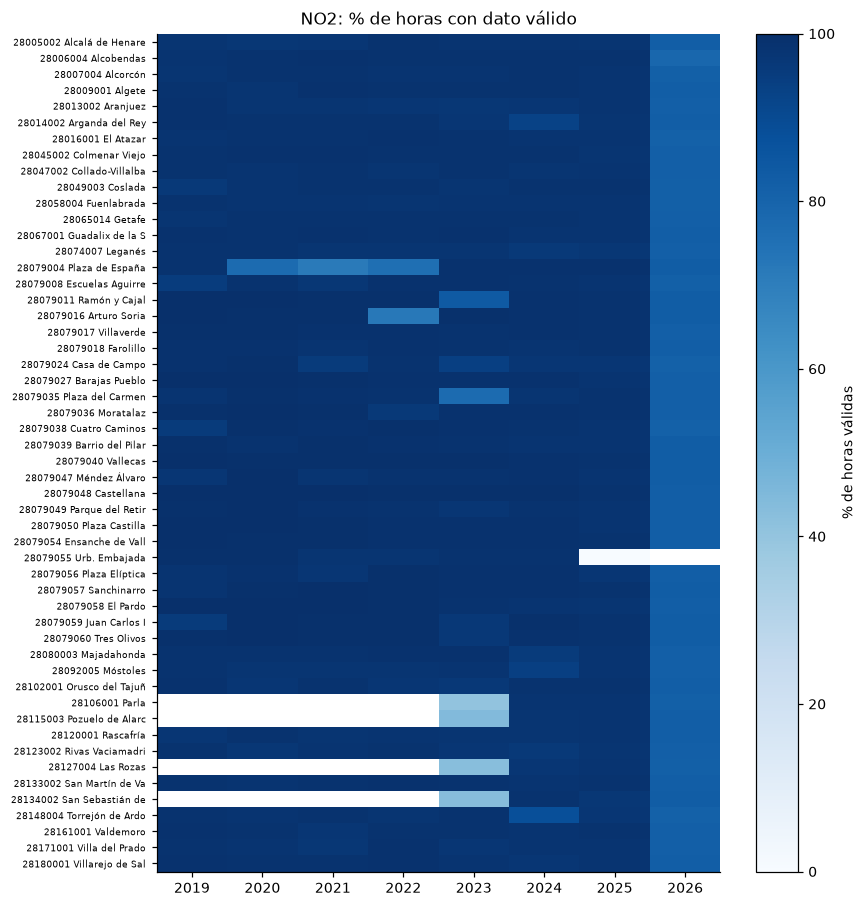

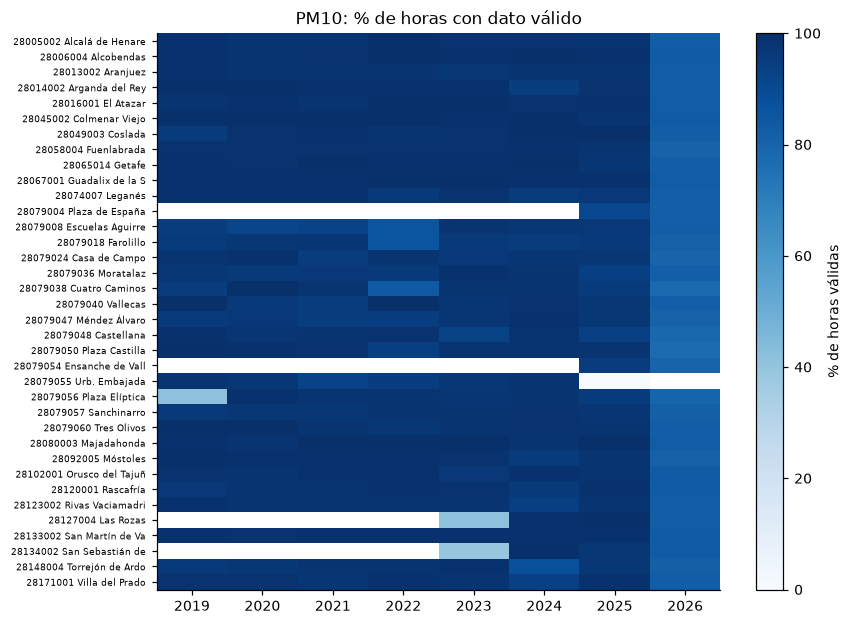

In [21]:
coverage_air = A.air_coverage(air)
for pollutant in ["NO2", "PM10"]:
    table = coverage_air.xs(pollutant, level="pollutant").unstack("year")
    fig, ax = plt.subplots(figsize=(8, max(3, len(table) * 0.16)))
    image = ax.imshow(table.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
    ax.set_yticks(range(len(table)), [f"{c} {stations.get(c, '')[:16]}" for c in table.index], fontsize=6)
    ax.set_xticks(range(len(table.columns)), table.columns)
    plt.colorbar(image, label="% de horas válidas"); ax.set_title(f"{pollutant}: % de horas con dato válido")
    plt.tight_layout(); plt.show()

In [22]:
gaps = A.air_gaps(air, min_hours=24 * 7)
gaps["estación"] = gaps["station_code"].map(stations)
print(f"Huecos de 7 días o más: {len(gaps)} · {gaps['days'].sum():.0f} días en total")
gaps.sort_values("days", ascending=False).head(12)

Huecos de 7 días o más: 62 · 1872 días en total


,station_code,pollutant,from,to,days,estación
2,28014002,O3,2022-01-01 00:00:00,2023-01-01 01:00:00,365.0,Arganda del Rey
13,28079004,NO2,2021-10-25 09:00:00,2022-03-25 12:00:00,151.1,Plaza de España
24,28079016,NO2,2022-06-09 11:00:00,2022-09-19 01:00:00,101.6,Arturo Soria
25,28079016,O3,2022-06-09 11:00:00,2022-09-19 01:00:00,101.6,Arturo Soria
32,28079035,NO2,2023-09-26 08:00:00,2023-12-01 14:00:00,66.2,Plaza del Carmen
33,28079035,O3,2023-09-26 08:00:00,2023-12-01 14:00:00,66.2,Plaza del Carmen
23,28079011,NO2,2023-01-09 09:00:00,2023-03-07 17:00:00,57.3,Ramón y Cajal
10,28079004,NO2,2020-03-03 10:00:00,2020-04-29 16:00:00,57.2,Plaza de España
26,28079018,PM10,2022-07-01 00:00:00,2022-08-17 01:00:00,47.0,Farolillo
19,28079008,PM10,2022-07-01 00:00:00,2022-08-16 18:00:00,46.8,Escuelas Aguirre


### 2.5 Horario de verano: ¿en qué hora está cada red?

Comprobación 1: el pico de NO2 de la mañana sigue al reloj (la gente va al
trabajo a la misma hora de reloj todo el año). Si un archivo estuviera en hora
fija, ese pico **cambiaría de hora** en el archivo con el cambio de hora.

In [23]:
comunidad_codes = [c for c in air["station_code"].cat.categories if not c.startswith("28079")]
city_codes = [c for c in air["station_code"].cat.categories if c.startswith("28079")]
for name, codes in (("Comunidad", comunidad_codes), ("Ayuntamiento", city_codes)):
    peaks = A.rush_hour_peak(air, codes)
    print(f"{name}: hora del pico de NO2 de la mañana (días laborables, 2 semanas a cada lado)")
    print(peaks.pivot_table(index="year", columns=["change", "side"], values="peak_hour").to_string(), "\n")

Comunidad: hora del pico de NO2 de la mañana (días laborables, 2 semanas a cada lado)
change marzo         octubre        
side   antes después   antes después
year                                
2019     8.0     7.0     7.0     8.0
2020     8.0     7.0     7.0     8.0
2021     8.0     7.0     7.0     8.0
2022     8.0     7.0     8.0     8.0
2023     8.0     7.0     7.0     8.0
2024     8.0     7.0     7.0     8.0
2025     8.0     7.0     7.0     8.0
2026     7.0     7.0     7.0     8.0 



Ayuntamiento: hora del pico de NO2 de la mañana (días laborables, 2 semanas a cada lado)
change marzo         octubre        
side   antes después   antes después
year                                
2019     9.0     9.0     9.0     9.0
2020     9.0     9.0     9.0     9.0
2021     9.0     9.0     9.0     9.0
2022     9.0     9.0     9.0     9.0
2023     9.0     9.0     9.0     9.0
2024     9.0     9.0     9.0     9.0
2025     9.0     9.0     9.0     9.0
2026     9.0     9.0     9.0     9.0 



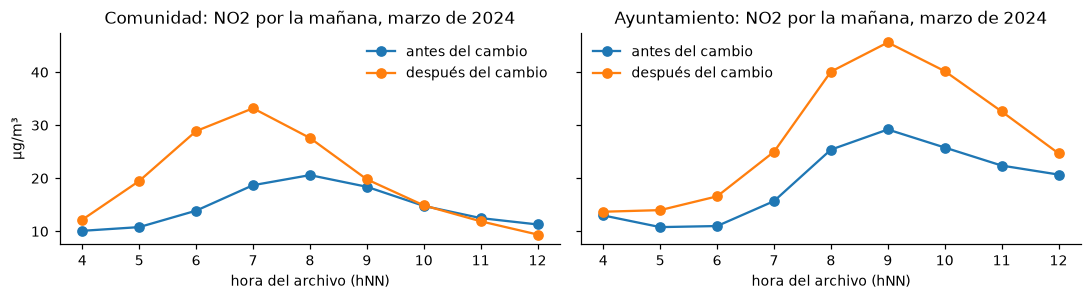

In [24]:
# Gráfico de un año: perfil de la mañana antes y después del cambio de marzo de 2024
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (name, codes) in zip(axes, (("Comunidad", comunidad_codes), ("Ayuntamiento", city_codes))):
    peaks = A.rush_hour_peak(air, codes)
    for _, row in peaks[(peaks["year"] == 2024) & (peaks["change"] == "marzo")].iterrows():
        profile = pd.Series(row["profile"])
        ax.plot(profile.index, profile.values, marker="o", label=f"{row['side']} del cambio")
    ax.set_title(f"{name}: NO2 por la mañana, marzo de 2024"); ax.set_xlabel("hora del archivo (hNN)"); ax.legend(frameon=False)
axes[0].set_ylabel("µg/m³"); plt.tight_layout(); plt.show()

Comprobación 2 (la decisiva): estaciones vecinas de las dos redes (a menos de
12 km) suben y bajan juntas. Buscamos el desfase en horas con el que mejor
coinciden, en invierno y en verano.

In [25]:
station_table = A.air_stations()
station_table["net"] = np.where(station_table["station_code"].str.startswith("28079"), "city", "com")
comunidad, city = station_table[station_table["net"] == "com"], station_table[station_table["net"] == "city"]
pairs = []
for _, a in comunidad.iterrows():
    distance = np.hypot((city["lat"] - a["lat"]) * 111, (city["lon"] - a["lon"]) * 85)
    nearest = distance.idxmin()
    if distance[nearest] < 12:
        pairs.append((a["station_code"], a["station"], city.loc[nearest, "station_code"], city.loc[nearest, "station"]))

no2 = valid[valid["pollutant"] == "NO2"].pivot(index="timestamp", columns="station_code", values="value")
no2.columns = no2.columns.astype(str)
rows = []
for c_code, c_name, m_code, m_name in pairs:
    for season, months in (("invierno", [11, 12, 1, 2]), ("verano", [5, 6, 7, 8])):
        part = no2[no2.index.month.isin(months)]
        a, b = part[c_code].diff(), part[m_code].diff()        # cambios hora a hora
        lag = max(range(-3, 4), key=lambda k: a.corr(b.shift(-k)))
        rows.append({"pareja": f"{c_name} / {m_name}", "estación": season, "desfase (h)": lag})
lags = pd.DataFrame(rows).pivot(index="pareja", columns="estación", values="desfase (h)")
lags

estación,invierno,verano
pareja,,
Alcobendas / Sanchinarro,1,2
Alcorcón / Villaverde,1,2
Coslada / Urb. Embajada,1,2
Fuenlabrada / Villaverde,1,2
Getafe / Villaverde,1,2
Las Rozas / El Pardo,1,2
Leganés / Villaverde,1,2
Majadahonda / Casa de Campo,1,2
Pozuelo de Alarcón / Casa de Campo,2,3


**Conclusión.** En la mayoría de parejas, la serie del Ayuntamiento coincide con la
de la Comunidad desplazada **1 hora en invierno y 2 en verano**: justo la diferencia
entre la hora UTC y la hora de Madrid. Los archivos horarios de la Comunidad
parecen estar en **UTC** y los del Ayuntamiento en **hora local**. Ver
`DATA_AUDIT.md` (problema A1) para lo que supone y la regla propuesta.

## 3. Tiempo (Open-Meteo)

Es la única fuente no oficial permitida. Comprobamos huecos, valores imposibles y
los días de cambio de hora.

In [26]:
for name, table, column, step in (("Diario (estaciones de polen)", daily_weather, "date", "D"),
                                  ("Horario (zonas del aire)", hourly_weather, "timestamp", "h")):
    table[column] = pd.to_datetime(table[column])
    expected = sum(len(pd.date_range(g[column].min(), g[column].max(), freq=step)) for _, g in table.groupby("place"))
    print(f"{name}: {len(table):,} filas · faltan {expected - len(table)} · vacíos {int(table.isna().sum().sum())} · duplicados {table.duplicated(['place', column]).sum()}")
    print(table.describe().loc[["min", "max"]].round(1).to_string(), "\n")
hourly_weather["day"] = hourly_weather["timestamp"].dt.normalize()
march = A._last_sunday(2024, 3)
print("Horas del 31/03/2024 (cambio de hora) en el archivo:",
      hourly_weather[(hourly_weather["place"] == "zone0") & (hourly_weather["day"] == march)]["timestamp"].dt.hour.tolist())

Diario (estaciones de polen): 86,555 filas · faltan 0 · vacíos 0 · duplicados 0
                    date  temp_mean  temp_max  rain  wind  humidity
min  1993-01-01 00:00:00       -4.9      -0.6   0.0   2.3      13.0
max  2026-11-08 00:00:00       34.5      43.4  95.2  52.0      99.0 

Horario (zonas del aire): 549,504 filas · faltan 0 · vacíos 0 · duplicados 0


               timestamp  temp  wind  rain  humidity  radiation
min  2019-01-01 00:00:00 -11.9   0.0   0.0       5.0        0.0
max  2026-11-01 23:00:00  43.1  49.4  23.1     100.0     1008.0 

Horas del 31/03/2024 (cambio de hora) en el archivo: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


El 31 de marzo de 2024 no existió la hora 02:00 en Madrid, pero el archivo tiene 24
horas, también la 2. Lo mismo pasa en los archivos de aire (siempre 24 columnas).
Afecta a dos días al año.

## 4. Resumen

Los problemas encontrados, cuánto afectan y la regla de limpieza propuesta están
en **`DATA_AUDIT.md`**. Nada de esto cambia todavía la aplicación ni los modelos.